# Female-headed households and income in Korea, 2005-2018

How much lower is the income of female-headed households, and how much of that gap is accounted for by age, education, household composition, work and occupation?

Data: Korea Income and Welfare panel (Kaggle extract of the Korea Welfare Panel Study), 92,857 household-year rows. Everything below is computed in this notebook with the `kwincome` package in `src/`. Every number in the text is printed by a cell in this notebook, and a check cell in Section 12 recomputes the numbers quoted in the summary and takeaways.

Extended from my 2025 IST256 (Syracuse University) course project. The re-audit and rebuild were done as a self-directed project with AI assistance (Claude).

**Contents:** 1 Summary · 2 What the data really is · 3 Cleaning · 4 Real income trend · 5 Raw gap and equivalization · 6 Staged regressions · 7 Oaxaca-Blinder decomposition · 8 Quantile gaps · 9 Context · 10 Regions · 11 Robustness · 12 Limitations · 13 Explore it yourself

In [1]:
%matplotlib inline
import time

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from kwincome import clean, features, geo, load, models, plots, stats
from kwincome.paths import FIG_DIR

plots.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
N_BOOT = 1000   # group medians (household-cluster bootstrap)
N_BOOT_OAXACA = 500

## 1. Question and summary of findings

**Question.** Female-headed households make up 30% of household-years in this panel. How much lower is their income, and how much of the gap lines up with observed differences in the head's age, education, household composition, work and occupation?

**Findings** (income unit is estimated and income year is inferred; all results are associations within this unweighted sample):

1. **Raw gap.** The median real equivalized income of female-headed households is 52% lower than that of male-headed households (Section 5). In the 2008-2017 model sample the gap in mean log income is 0.621 log points, about 46% lower (Section 6).
2. **Controls shrink it to about 7%.** With age, education, household size, marital status, work/occupation, region and year, the gap falls to -7.3% (95% CI -10.1% to -4.5%, household-clustered).
3. **Decomposition (headline).** Differences in observed characteristics account for 88% of the log gap (85% to 91% depending on the reference coefficients). Work/occupation (29% of the log gap) and education (28%) are the largest pieces; 0.076 log points (12% of the log gap, 95% CI 0.045 to 0.107) remain unexplained. Age, education and work/occupation alone account for 69% of the log gap; the rest of the explained part is household makeup and marital status. Read "explained" as composition, not independent causes: marital status and household size (19% of the log gap together) largely restate what female headship means here, since 68% of female-headed household-years (all years) are widowed heads, typically older and living alone. The unexplained part is a residual, not a measure of discrimination.
4. **Across the distribution.** At conditional quantiles (given all controls) the gap is 6% to 11%, widest at the 90th percentile (quantile CIs are not household-clustered).
5. **Robust to specification.** Winsorizing, dropping equivalization, or using all years without occupation keeps the controlled gap between -7.2% and -8.2%.
6. **Measurement matters.** Female-headed households are much smaller (1.50 vs 2.90 people; 68% live alone). Computed in this notebook with the original course notebook's metric (income / household size), the gap would be only 29%. Equivalized income sits between household and per-person income.

## 2. Data and what it really is

*Takeaway: this is a panel of 10,046 households observed up to 14 times (data years 2005-2018, Kaggle `year`); person attributes describe the household head, income is household income, the unit is most plausibly 10k KRW per year (estimated), and there are no survey weights. Marital status labels are inferred: code 2 (Widowed) heads are 89% female, median age 74, median household size 1.*

The file has one row per household and survey year. The person attributes (gender, birth year, education, occupation) describe that year's **household head**, and `income` is household income, so every comparison here is between households, not between men and women.

In [2]:
raw = load.load_raw()
job_codes = load.load_job_codes()

waves = raw.groupby("id")["year"].nunique()
per_id = raw.groupby("id").agg(n_gender=("gender", "nunique"), n_born=("year_born", "nunique"))
head_change = (per_id["n_gender"] > 1) | (per_id["n_born"] > 1)
share = raw["gender"].map({1: "male", 2: "female"}).value_counts(normalize=True)

facts = pd.Series({
    "rows (household-years)": len(raw),
    "households in 2005 (wave 1)": raw.loc[raw["year"].eq(2005), "id"].nunique(),
    "households (id)": raw["id"].nunique(),
    "data years (Kaggle `year`)": f"{raw['year'].min()}-{raw['year'].max()}",
    "max waves per household": waves.max(),
    "households observed in all 14 waves": int((waves == 14).sum()),
    "ids whose head gender or birth year changes": int(head_change.sum()),
    "  of which head gender changes": int((per_id["n_gender"] > 1).sum()),
    "male / female head share of rows": f"{share['male']:.0%} / {share['female']:.0%}",
    "income < 0 (rows)": int((raw["income"] < 0).sum()),
    "income == 0 (rows)": int((raw["income"] == 0).sum()),
    "income min": f"{raw['income'].min():,.0f}",
    "income median": f"{raw['income'].median():,.0f}",
    "income max": f"{raw['income'].max():,.0f}",
    "survey-weight column present": any("weight" in c.lower() or "wgt" in c.lower() for c in raw.columns),
}, name="value")
facts.to_frame()

,value
rows (household-years),92857
households in 2005 (wave 1),7072
households (id),10046
data years (Kaggle `year`),2005-2018
max waves per household,14
households observed in all 14 waves,4018
ids whose head gender or birth year changes,1428
of which head gender changes,1284
male / female head share of rows,70% / 30%
income < 0 (rows),199


In [3]:
n_change, n_gender_change = int(head_change.sum()), int((per_id["n_gender"] > 1).sum())
head_text = (f"**Why the head changes.** {n_change:,} ids change head gender or birth year across waves "
             f"({n_gender_change:,} change head gender), for example when a husband dies and his wife "
             f"becomes the head. That is most consistent with `id` being a household and the attributes "
             f"belonging to whoever heads it that year. Bootstrap confidence intervals and regression "
             f"standard errors are therefore clustered by household.")
display(Markdown(head_text))

**Why the head changes.** 1,428 ids change head gender or birth year across waves (1,284 change head gender), for example when a husband dies and his wife becomes the head. That is most consistent with `id` being a household and the attributes belonging to whoever heads it that year. Bootstrap confidence intervals and regression standard errors are therefore clustered by household.

**Marital status codes (labels inferred).** The data ships marital status as codes 1-6 without labels. The labels used here (1 Married, 2 Widowed, 3 Divorced, 4 Separated, 5 Never married, 6 Other) follow the source survey's usual coding convention and fit the profile below; they are an inference, not confirmed from a codebook. Codes 0 and 9 are treated as nonresponse.

In [4]:
from kwincome.codes import MARRIAGE

mar = raw.assign(age=raw["year"] - raw["year_born"], female=raw["gender"].eq(2)).groupby("marriage").agg(
    n=("id", "size"), female_head_share=("female", "mean"), median_head_age=("age", "median"),
    median_household_size=("family_member", "median"))
mar.insert(0, "label used", mar.index.map(lambda c: MARRIAGE.get(c, "nonresponse (missing)")))
display(mar.style.format({"n": "{:,}", "female_head_share": "{:.0%}", "median_head_age": "{:.0f}",
                          "median_household_size": "{:.0f}"}))
wid = mar.loc[2]
print(f"code 2 (Widowed): {wid['female_head_share']:.0%} female-headed, median head age "
      f"{wid['median_head_age']:.0f}, median household size {wid['median_household_size']:.0f}; "
      f"code 1: {mar.loc[1, 'female_head_share']:.0%} female-headed, size {mar.loc[1, 'median_household_size']:.0f}; "
      f"code 5 median head age {mar.loc[5, 'median_head_age']:.0f}")
fem_widowed = raw.loc[raw["gender"].eq(2), "marriage"].eq(2).mean()
print(f"share of female-headed household-years with code 2 (Widowed): {fem_widowed:.0%}")

,label used,n,female_head_share,median_head_age,median_household_size
marriage,,,,,
0,nonresponse (missing),14,21%,17,1
1,Married,"57,151",3%,55,3
2,Widowed,"21,218",89%,74,1
3,Divorced,"7,473",56%,54,2
4,Separated,"1,151",58%,57,2
5,Never married,"5,788",36%,36,1
6,Other,55,24%,67,2
9,nonresponse (missing),7,57%,63,1


code 2 (Widowed): 89% female-headed, median head age 74, median household size 1; code 1: 3% female-headed, size 3; code 5 median head age 36
share of female-headed household-years with code 2 (Widowed): 68%


**Income unit (estimated).** The data has no codebook. Below, the median household income by data year is read as 10,000 KRW (만원) per year.

In [5]:
unit = raw.groupby("year")["income"].median().to_frame("median income (raw units)")
unit["if 10k KRW per year: KRW million"] = unit.iloc[:, 0] / 100
unit["if 1k KRW per year: KRW million"] = unit.iloc[:, 0] / 1000
unit["if 10k KRW per month: KRW million per year"] = unit.iloc[:, 0] * 12 / 100
unit.loc[[2005, 2010, 2018]].round(1)

,median income (raw units),if 10k KRW per year: KRW million,if 1k KRW per year: KRW million,if 10k KRW per month: KRW million per year
year,,,,
2005,1721.0,17.2,1.7,206.5
2010,2582.0,25.8,2.6,309.8
2018,2987.0,29.9,3.0,358.4


Only the first reading gives a plausible annual household income (about 30 million KRW in 2018); the other two are implausibly low or high. The unit is still an inference, so every income figure in this notebook is labelled "estimated". **Income year (inference).** Kaggle `year` appears to be the income reference year already: year 2005 (wave 1) has exactly 7,072 households, the size of the source survey's first wave, which was fielded in 2006 and asked about 2005 income; and 1,878 new ids appear in year 2011 (wave 7), consistent with the refresh sample fielded in 2012. So **income year = Kaggle `year`** (fielded the following year), and incomes are deflated to 2018 prices with that year's World Bank CPI for Korea. Neither reading is confirmed by a codebook.

**No survey weights.** The source survey is reported to oversample low-income households and to ship sampling weights; this Kaggle version has no weight column (checked above). Results are comparisons within this sample, not national estimates.

**Outliers.** Negative and zero incomes are kept for medians and excluded only from log models (counted where they are dropped). The maximum is far above the median, which is why the notebook uses medians and log income, and reruns the models with winsorized income in Section 11.

## 3. Cleaning report

*Takeaway: no rows are dropped; 89.8% of coded occupation rows match a job title, and almost all unmatched rows sit in data years 2005-2007, so occupation is only used for 2008-2017.*

Blank strings and non-response codes (for example 99 for company size and non-work reason, 9 for marriage) become missing values; codes become labels through lookup tables; occupation codes are merged with the provided English job-title table. No rows are dropped at this stage.

In [6]:
df, report = clean.clean(raw, job_codes)
cpi = features.load_cpi()
df = features.add_features(df, cpi)

print(f"rows after cleaning: {report['n_rows']:,} (none dropped)")
print(f"occupation codes matched to a job title: {report['occupation_mapping_rate']:.1%} of coded rows")
print(f"distinct unmapped codes: {len(report['unmapped_codes'])}")
print(f"rows with income <= 0 (excluded from log models only): {int((df['income'] <= 0).sum()):,}")

rows after cleaning: 92,857 (none dropped)
occupation codes matched to a job title: 89.8% of coded rows
distinct unmapped codes: 94


rows with income <= 0 (excluded from log models only): 232


**Occupation codes change meaning around 2008.** The unmapped codes are not spread evenly: they concentrate in data years 2005-2007, and the occupation mix jumps between 2007 and 2008 while it moves slowly in every other year. This looks like a change of occupation classification between those waves (an inference). Models and charts that use occupation therefore use **data years 2008-2017 only**; 2018 is excluded too because it again has unmapped codes.

In [7]:
coded = df[df["occupation_code"].notna()]
by_year = coded.groupby("year").agg(
    coded_rows=("occupation_code", "size"),
    unmapped_rows=("occupation_label", lambda s: int((s == "Unmapped").sum())))
by_year["unmapped_share"] = by_year["unmapped_rows"] / by_year["coded_rows"]
mix = pd.crosstab(coded["year"], coded["occupation_major"], normalize="index")
mix.columns = [f"major {c}" for c in mix.columns]
jump = (mix.diff().abs().sum(axis=1) / 2).rename("mix change vs prior year")
display(by_year.join(jump).style.format(
    {"unmapped_share": "{:.1%}", "mix change vs prior year": "{:.1%}"}))

,coded_rows,unmapped_rows,unmapped_share,mix change vs prior year
year,,,,
2005,4773,2100,44.0%,0.0%
2006,4410,1926,43.7%,1.7%
2007,4212,1899,45.1%,0.8%
2008,4038,2,0.0%,6.2%
2009,3958,0,0.0%,2.0%
2010,3763,0,0.0%,0.7%
2011,4781,0,0.0%,1.6%
2012,4645,0,0.0%,0.9%
2013,4441,0,0.0%,1.3%


In [8]:
from kwincome.codes import OCC_MAJOR

examples = (job_codes.assign(major=clean.occupation_major(job_codes["job_code"]))
            .groupby("major")["job_title"].agg(lambda s: "; ".join(s.head(2))))
pd.DataFrame({"label used here": pd.Series(OCC_MAJOR), "first titles in the mapping table": examples})

,label used here,first titles in the mapping table
1,Managers,"Assembly members, senior public officials and ..."
2,Professionals,Life and natural science experts; Humanities a...
3,Clerks,Administrative clerk; Management-related clerk
4,Service workers,"Police, fire and prison related workers; Secur..."
5,Sales workers,Salesperson; Store salesperson
6,Agriculture and fishery,Crop cultivation worker; Horticultural and lan...
7,Craft and trades,Food processing related personnel; Textile and...
8,Machine operators,Food processing related machine operator; Beve...
9,Elementary occupations,Simple workers in construction and mining; Unl...
A,Armed forces,Military officer; Long-term sergeant and warra...


Major-group labels follow the first digit of the Korean Standard Classification of Occupations; the titles in the mapping table agree with that reading. Two exceptions to the first-digit rule: 4-digit codes starting with 10 (1011 military officer, 1012 long-term sergeant) are grouped as "Armed forces" (A) instead of Managers, and 9999 (no title in the table) is treated as missing instead of Elementary. Occupation-year coverage: `occ_consistent` marks data years 2008-2017.

## 4. Real income trend, income years 2005-2018

*Takeaway: the real equivalized median rose 58% between income years 2005 and 2018, and female-headed households stayed at 45% to 51% of the male-headed median in every year. The panel's median head age rose from 53 to 64 and 1,878 households joined in 2011, so this is the panel's trend, not Korea's.*

Measure: real equivalized household income, income / sqrt(household size), in 2018 prices (estimated unit: 10k KRW per year). Income year = Kaggle `year`, which appears to be the income reference year (fielded the following year).

In [9]:
t0 = time.time()
trend_all = stats.median_ci_by_group(df, "income_year", "eq_income", n_boot=N_BOOT)
trend_gender = stats.median_ci_by_group(df, ["income_year", "gender_label"], "eq_income", n_boot=N_BOOT)
print(f"bootstrap time: {time.time() - t0:.0f}s")

trend = pd.concat([trend_all.assign(gender_label="All households"), trend_gender])
wide = trend.pivot(index="income_year", columns="gender_label", values="median")
wide["female / male"] = wide["Female"] / wide["Male"]
first, last = wide.index.min(), wide.index.max()
growth = wide.loc[last, "All households"] / wide.loc[first, "All households"] - 1
ratio_lo, ratio_hi = wide["female / male"].min(), wide["female / male"].max()
print(f"median {first}: {wide.loc[first, 'All households']:,.0f}  ->  {last}: "
      f"{wide.loc[last, 'All households']:,.0f}  ({growth:+.0%})")
print(f"female-headed median as share of male-headed: {ratio_lo:.0%} to {ratio_hi:.0%} across years")
wide.round(2)

bootstrap time: 11s
median 2005: 1,373  ->  2018: 2,167  (+58%)
female-headed median as share of male-headed: 45% to 51% across years


gender_label,All households,Female,Male,female / male
income_year,,,,
2005,1373.48,801.84,1647.74,0.49
2006,1588.90,889.75,1908.39,0.47
2007,1706.15,989.47,2041.18,0.48
2008,1769.23,1021.13,2109.00,0.48
2009,1825.53,1114.74,2183.80,0.51
2010,1887.71,1115.13,2301.27,0.48
2011,1770.13,1038.83,2204.89,0.47
2012,1848.02,1072.92,2306.34,0.47
2013,1811.22,1024.85,2299.12,0.45


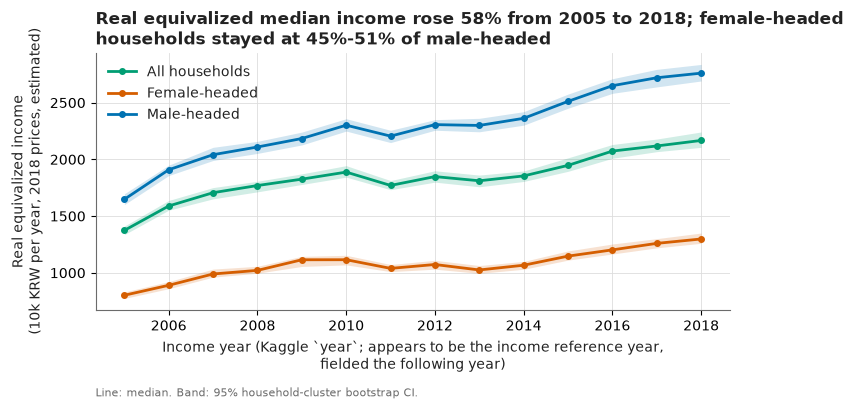

In [10]:
fig = plots.plot_trend(
    trend.rename(columns={"income_year": "Income year"}), x="Income year", hue="gender_label",
    title=(f"Real equivalized median income rose {growth:.0%} from {first} to {last}; female-headed\n"
           f"households stayed at {ratio_lo:.0%}-{ratio_hi:.0%} of male-headed"),
    ylabel=f"Real equivalized income\n({plots.INCOME_LABEL})")
ax = fig.axes[0]
ax.set_xlabel("Income year (Kaggle `year`; appears to be the income reference year,\n"
              "fielded the following year)")
for t in ax.texts:
    if t.get_text().startswith("Line: median"):
        t.set_y(-0.30)
fig.tight_layout()
for t in ax.get_legend().get_texts():
    t.set_text({"Male": "Male-headed", "Female": "Female-headed"}.get(t.get_text(), t.get_text()))
plots.save(fig, "trend");

**Who is in the panel changes over time.** The trend follows the households in this panel, not Korea. The table shows when each id first appears, the number of rows per data year and the median head age.

In [11]:
first_seen = raw.groupby("id")["year"].min().value_counts().sort_index().rename("ids first seen")
panel = pd.concat([first_seen, raw.groupby("year").size().rename("rows"),
                   raw.assign(age=raw["year"] - raw["year_born"]).groupby("year")["age"].median()
                   .rename("median head age")], axis=1).fillna(0).astype(int)
display(panel.T)
new_2011 = int(panel.loc[2011, "ids first seen"])
other_new = panel.loc[2006:2018, "ids first seen"].drop(2011)
age_first, age_last = panel["median head age"].iloc[0], panel["median head age"].iloc[-1]
print(f"new ids in 2011: {new_2011:,} (other years after 2005: {other_new.min()}-{other_new.max()}); "
      f"median head age {age_first} in 2005 -> {age_last} in 2018")

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
ids first seen,7072,69,126,105,110,72,1878,85,74,87,95,106,84,83
rows,7072,6580,6314,6207,6034,5735,7532,7312,7048,6914,6723,6581,6474,6331
median head age,53,54,56,56,57,58,60,60,61,62,63,63,64,64


new ids in 2011: 1,878 (other years after 2005: 69-126); median head age 53 in 2005 -> 64 in 2018


Almost all households enter in 2005, then a large group joins in 2011, which appears consistent with the new sample the source survey is reported to have added that year. Between refreshes the panel ages and loses households, so the trend mixes real income growth with changes in who is observed.

## 5. The raw gap, and why equivalized income

*Takeaway: on the equivalized measure the female-headed median is 52% lower; per-person income would shrink the gap to 29% because female-headed households are about half the size (1.50 vs 2.90 people).*

The 52% here is a gap in medians over all years; the regressions below measure a gap in mean log income for 2008-2017 (0.621 log points, about 46%), so the two numbers are not expected to match.

The original course notebook compared `income_per_person` (income / household size). Dividing by the full household size assumes no economies of scale: a two-person household would need twice the income of a single person for the same living standard. The OECD square-root scale (income / sqrt(size)) is the common middle ground. Because female-headed households are much smaller, the choice changes the size of the gap.

In [12]:
measures = {"real_income": "household income (no adjustment)",
            "eq_income": "equivalized: income / sqrt(size)",
            "income_pp": "per person: income / size"}
rows = []
for col, name in measures.items():
    s = stats.median_ci_by_group(df, "gender_label", col, n_boot=N_BOOT).set_index("gender_label")
    rows.append({"measure": name, "male-headed median": s.loc["Male", "median"],
                 "female-headed median": s.loc["Female", "median"],
                 "gap (female vs male)": s.loc["Female", "median"] / s.loc["Male", "median"] - 1})
gap_table = pd.DataFrame(rows).set_index("measure")
size = df.groupby("gender_label")["family_member"].agg(["mean", lambda s: (s == 1).mean()])
size.columns = ["mean household size", "share single-person"]
display(gap_table.style.format({"male-headed median": "{:,.0f}", "female-headed median": "{:,.0f}",
                                "gap (female vs male)": "{:+.0%}"}))
display(size.style.format({"mean household size": "{:.2f}", "share single-person": "{:.0%}"}))

,male-headed median,female-headed median,gap (female vs male)
measure,,,
household income (no adjustment),"3,797","1,205",-68%
equivalized: income / sqrt(size),"2,257","1,080",-52%
per person: income / size,"1,328",943,-29%


,mean household size,share single-person
gender_label,,
Female,1.50,68%
Male,2.90,10%


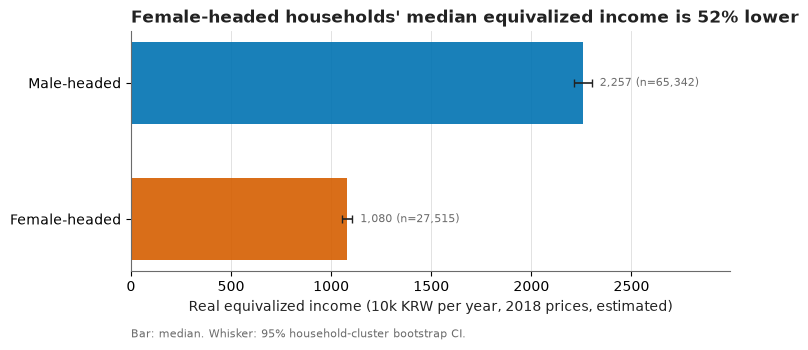

In [13]:
raw_gap = (stats.median_ci_by_group(df, "gender_label", "eq_income", n_boot=N_BOOT)
           .set_index("gender_label").loc[["Male", "Female"]].reset_index())
eq_gap = gap_table.loc["equivalized: income / sqrt(size)", "gap (female vs male)"]
pp_gap = gap_table.loc["per person: income / size", "gap (female vs male)"]
fig = plots.plot_ci_bars(raw_gap, x="gender_label",
                         title=f"Female-headed households' median equivalized income is {-eq_gap:.0%} lower",
                         xlabel=f"Real equivalized income ({plots.INCOME_LABEL})")
fig.axes[0].set_yticks(range(len(raw_gap)), [f"{g}-headed" for g in raw_gap["gender_label"]])
fig.set_size_inches(7.5, 3.6)
for t in fig.axes[0].texts:
    if t.get_text().startswith("Bar: median"):
        t.set_y(-0.24)
fig.tight_layout()
plots.save(fig, "raw_gap");

## 6. Staged regressions: how far do controls shrink the gap?

*Takeaway: the controlled gap falls from -46% to -7% (-7.3%, 95% CI -10.1% to -4.5%); age, education, household size and marital status account for most of the fall in entry order (see the order-dependence note below), and adding region and year widens it slightly (from -6.0% to -7.3%).*

Outcome: log real equivalized income. Coefficient on a female-head dummy as control blocks are added in a fixed order, all on the same rows (data years 2008-2017, income > 0). Standard errors are clustered by household. Percent gap = exp(coefficient) - 1. These are associations, not causal effects.

In [14]:
mf, n_dropped = models.model_frame(df)
print(f"model sample: {len(mf):,} rows, {mf['id'].nunique():,} households, data years "
      f"{mf['year'].min()}-{mf['year'].max()}; dropped for income <= 0: {n_dropped:,}")
staged = models.staged_gap(df)
staged.style.format({"coef": "{:.3f}", "se": "{:.3f}", "pct_gap": "{:.1f}%",
                     "ci_low_pct": "{:.1f}%", "ci_high_pct": "{:.1f}%", "n": "{:,}"})

model sample: 66,449 rows, 8,814 households, data years 2008-2017; dropped for income <= 0: 111


,step,coef,se,pct_gap,ci_low_pct,ci_high_pct,n
0,Raw,-0.621,0.013,-46.3%,-47.6%,-44.9%,"66,449"
1,+ Age,-0.381,0.012,-31.7%,-33.2%,-30.1%,"66,449"
2,+ Education,-0.239,0.012,-21.2%,-23.1%,-19.4%,"66,449"
3,+ Household size,-0.155,0.013,-14.3%,-16.5%,-12.1%,"66,449"
4,+ Marital status,-0.077,0.017,-7.4%,-10.5%,-4.3%,"66,449"
5,+ Work / occupation,-0.062,0.015,-6.0%,-8.8%,-3.1%,"66,449"
6,+ Region & year,-0.076,0.015,-7.3%,-10.1%,-4.5%,"66,449"


raw: -0.621 log points (-46.3%); all controls: -0.076 (-7.3%, 95% CI -10.1% to -4.5%)


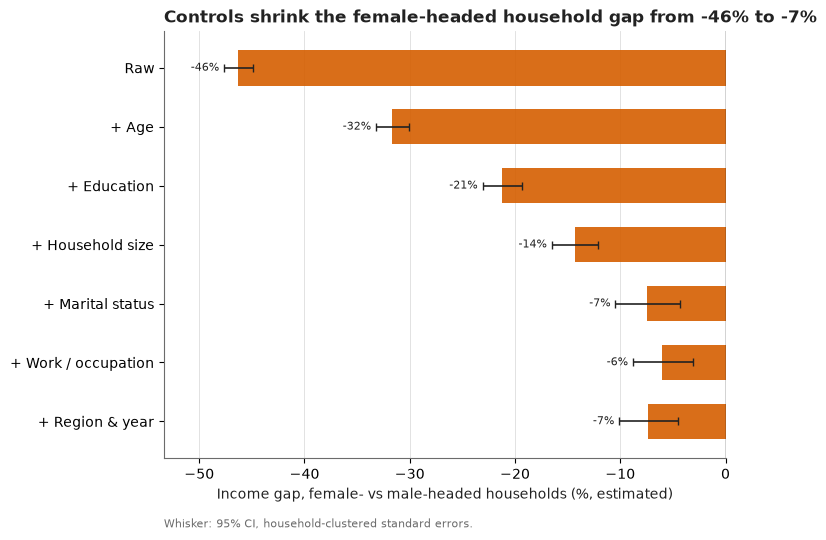

In [15]:
s_raw, s_fin = staged.iloc[0], staged.iloc[-1]
print(f"raw: {s_raw['coef']:.3f} log points ({s_raw['pct_gap']:.1f}%); "
      f"all controls: {s_fin['coef']:.3f} ({s_fin['pct_gap']:.1f}%, 95% CI "
      f"{s_fin['ci_low_pct']:.1f}% to {s_fin['ci_high_pct']:.1f}%)")
fig = plots.plot_staged(staged, title=(f"Controls shrink the female-headed household gap from "
                                       f"{s_raw['pct_gap']:.0f}% to {s_fin['pct_gap']:.0f}%"))
plots.save(fig, "staged_gap");

The size of each step depends on the order in which blocks enter (age first takes credit that education might otherwise get). The decomposition in the next section does not depend on order.

## 7. Oaxaca-Blinder decomposition (headline)

*Takeaway: observed characteristics account for 88% of the 0.621 log-point gap; work/occupation (0.181) and education (0.171) are the largest pieces, and 0.076 log points (12% of the log gap) remain unexplained. Marital status and household size together are 19% of the log gap and mostly describe what a female-headed household is, so the explained share is composition, not a list of causes.*

Pooled two-fold decomposition (Neumark / Jann): one regression on all households with a female-head dummy supplies the reference coefficients; the explained part is the difference in average characteristics times those coefficients, split by variable group. Same sample and controls as the last staged step. 95% CIs from a household-cluster bootstrap with 500 draws.

Reading the numbers: contributions are in **log points** and their shares are **shares of the log gap**. The percent income difference exp(gap) - 1 is a different quantity; the two are shown side by side below but do not add up to each other.

In [16]:
t0 = time.time()
oax = models.oaxaca(df, n_boot=N_BOOT_OAXACA)
print(f"bootstrap time: {time.time() - t0:.0f}s")
T, E, U = oax["total"], oax["explained"], oax["unexplained"]
ci = oax["ci"]
summary = pd.DataFrame({
    "log points": [T, E, U],
    "95% CI": [f"[{ci[k][0]:.3f}, {ci[k][1]:.3f}]" for k in ("total", "explained", "unexplained")],
    "share of the log gap": [1.0, E / T, U / T],
}, index=["total gap (male minus female)", "explained", "unexplained"])
contrib = oax["contrib"].assign(share_of_log_gap=lambda d: d["explained"] / T).set_index("group")
display(summary.style.format({"log points": "{:.3f}", "share of the log gap": "{:.1%}"}))
display(contrib.sort_values("explained", ascending=False).style.format("{:.3f}").format(
    "{:.1%}", subset=["share_of_log_gap"]))
print(f"As a % income difference (a different quantity): male-headed households' mean log income "
      f"implies about {np.expm1(T):.0%} higher income; the unexplained part alone corresponds to "
      f"male-headed {np.expm1(U):.1%} higher, i.e. female-headed {-np.expm1(-U):.1%} lower.")
print(f"Check: unexplained ({U:.3f}) equals minus the final staged coefficient "
      f"({-s_fin['coef']:.3f}), as expected for the pooled decomposition with a group dummy.")

bootstrap time: 74s


,log points,95% CI,share of the log gap
total gap (male minus female),0.621,"[0.596, 0.646]",100.0%
explained,0.545,"[0.515, 0.575]",87.7%
unexplained,0.076,"[0.045, 0.107]",12.3%


,explained,ci_low,ci_high,share_of_log_gap
group,,,,
Work / occupation,0.181,0.167,0.196,29.1%
Education,0.171,0.153,0.188,27.5%
Age,0.076,0.065,0.087,12.2%
Marital status,0.068,0.043,0.094,11.0%
Household size,0.051,0.036,0.064,8.2%
Region & year,-0.001,-0.005,0.003,-0.2%


As a % income difference (a different quantity): male-headed households' mean log income implies about 86% higher income; the unexplained part alone corresponds to male-headed 7.9% higher, i.e. female-headed 7.3% lower.
Check: unexplained (0.076) equals minus the final staged coefficient (0.076), as expected for the pooled decomposition with a group dummy.


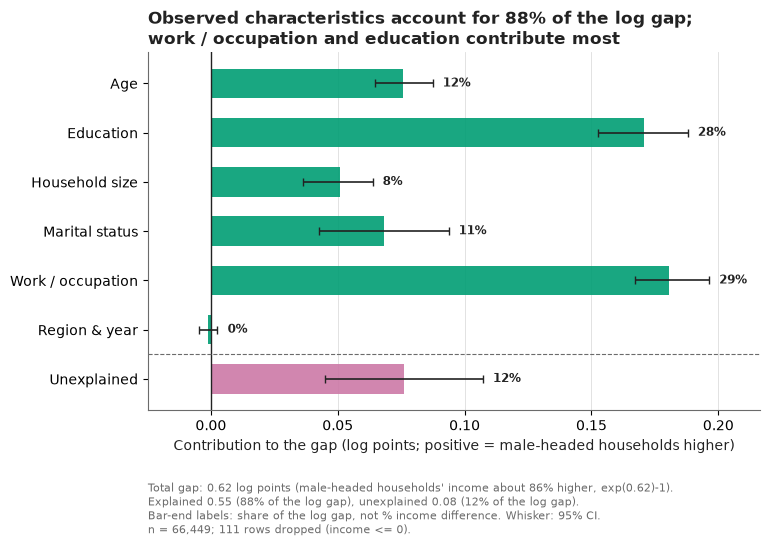

In [17]:
top2 = contrib["explained"].nlargest(2)
fig = plots.plot_oaxaca(oax, title=(f"Observed characteristics account for {E / T:.0%} of the log gap;\n"
                                    f"{top2.index[0].lower()} and {top2.index[1].lower()} "
                                    f"contribute most"))
plots.save(fig, "oaxaca");

In [18]:
comp = contrib.loc[["Marital status", "Household size"], "explained"].sum()
head_chars = contrib.loc[["Age", "Education", "Work / occupation"], "explained"].sum()
display(Markdown(
    f"**How to read the explained part.** It is composition, not a list of independent causes. Marital "
    f"status and household size together contribute {comp:.3f} log points ({comp / T:.0%} of the log gap), "
    f"and they largely restate what female headship means here: many female-headed households are widowed "
    f"older women living alone (Section 2), with no spouse and fewer potential earners. Age, education "
    f"and work/occupation alone account for {head_chars:.3f} log points ({head_chars / T:.0%} of the log "
    f"gap). Education and "
    f"work/occupation describe the head only, while income is household-wide.\n\n"
    f"The unexplained part is what remains after these controls. It is not a measure of discrimination: it "
    f"also absorbs anything unobserved (hours worked, wealth, transfers, who becomes the household head and why)."))

**How to read the explained part.** It is composition, not a list of independent causes. Marital status and household size together contribute 0.119 log points (19% of the log gap), and they largely restate what female headship means here: many female-headed households are widowed older women living alone (Section 2), with no spouse and fewer potential earners. Age, education and work/occupation alone account for 0.427 log points (69% of the log gap). Education and work/occupation describe the head only, while income is household-wide.

The unexplained part is what remains after these controls. It is not a measure of discrimination: it also absorbs anything unobserved (hours worked, wealth, transfers, who becomes the household head and why).

## 8. Quantile gaps: is the gap the same across the distribution?

*Takeaway: at conditional quantiles (given all controls) the gap is 6% to 9% from the 10th to the 75th percentile and about 11% at the 90th; these CIs are not clustered and likely too narrow, so treat the pattern as suggestive.*

Quantile regressions at the 10th, 25th, 50th, 75th and 90th conditional percentiles (of log income given the full control set, not of the raw income distribution) (same sample as Sections 6-7). **The confidence intervals here are statsmodels defaults and are not clustered by household**, so with repeated households they are likely too narrow.

fit time: 24s


,q,coef,ci_low,ci_high,pct_gap,n
0,0.10,-0.092,-0.113,-0.071,-8.8%,"66,449"
1,0.25,-0.065,-0.081,-0.049,-6.3%,"66,449"
2,0.50,-0.075,-0.091,-0.060,-7.3%,"66,449"
3,0.75,-0.083,-0.102,-0.065,-8.0%,"66,449"
4,0.90,-0.119,-0.142,-0.095,-11.2%,"66,449"


controlled gap: 6.3% to 11.2% lower; widest at the 90% conditional quantile


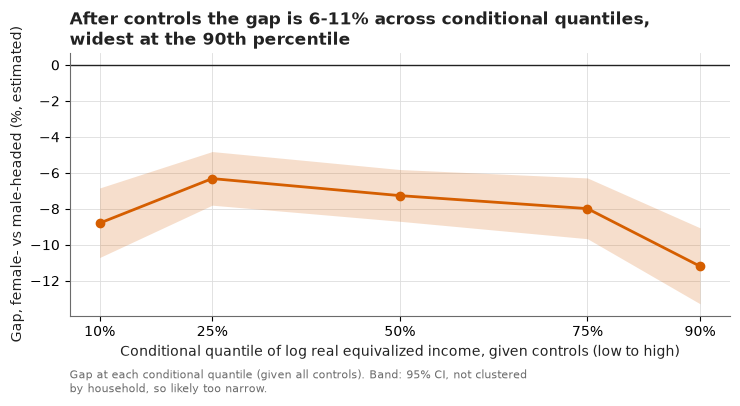

In [19]:
t0 = time.time()
qgap = models.quantile_gap(df)
print(f"fit time: {time.time() - t0:.0f}s")
q_small, q_big = -qgap["pct_gap"].max(), -qgap["pct_gap"].min()
q_widest = qgap.loc[qgap["pct_gap"].idxmin(), "q"]
display(qgap.style.format({"q": "{:.2f}", "coef": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                           "pct_gap": "{:.1f}%", "n": "{:,}"}))
print(f"controlled gap: {q_small:.1f}% to {q_big:.1f}% lower; widest at the {q_widest:.0%} conditional quantile")
fig = plots.plot_quantiles(qgap, title=(f"After controls the gap is {q_small:.0f}-{q_big:.0f}% across conditional "
                                        f"quantiles,\nwidest at the {q_widest * 100:.0f}th percentile"))
plots.save(fig, "quantile_gap");

## 9. Context: who has lower and higher incomes

*Takeaway: education and age line up with large income differences, and the lowest-income occupations have far more female heads (53% on average in the bottom 10 vs 6% in the top 10), consistent with work/occupation being the largest explained piece in Section 7. Non-work reason codes are profiled label-free because their documented labels conflict with the data (code 4, documented as preparing for school, is 95% female-headed with median head age 68).*

Median real equivalized income by group with household-cluster bootstrap 95% CIs. Groups with fewer than 100 household-years are suppressed. Occupation charts use data years 2008-2017 (see Section 3); the other charts use all years.

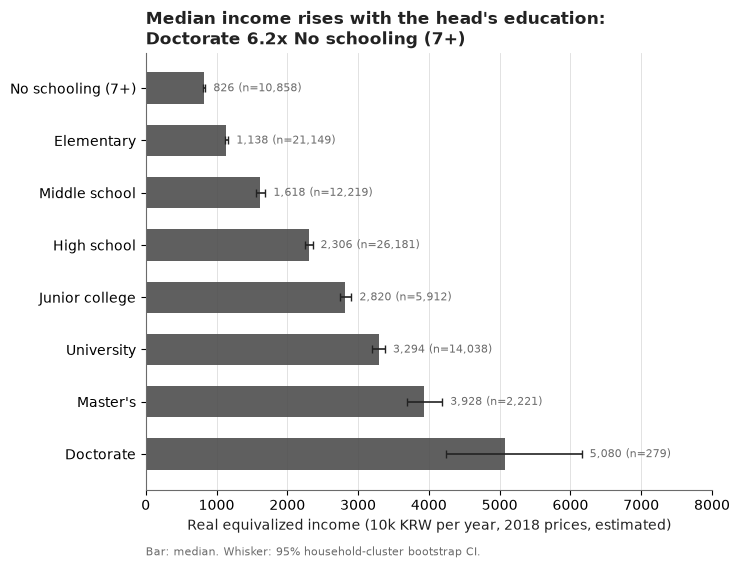

In [20]:
def ci_chart(data, group, title_fmt, fig_name, sort=False):
    s = stats.median_ci_by_group(data, group, "eq_income", n_boot=N_BOOT)
    if sort:
        s = s.sort_values("median", ascending=False).reset_index(drop=True)
    hi, lo = s.loc[s["median"].idxmax()], s.loc[s["median"].idxmin()]
    title = title_fmt.format(hi=plots.pretty_label(hi[group]), lo=plots.pretty_label(lo[group]),
                             ratio=hi["median"] / lo["median"])
    fig = plots.plot_ci_bars(s, x=group, title=title,
                             xlabel=f"Real equivalized income ({plots.INCOME_LABEL})")
    plots.save(fig, fig_name)
    return s

edu = ci_chart(df, "education_label",
               "Median income rises with the head's education:\n{hi} {ratio:.1f}x {lo}",
               "context_education")

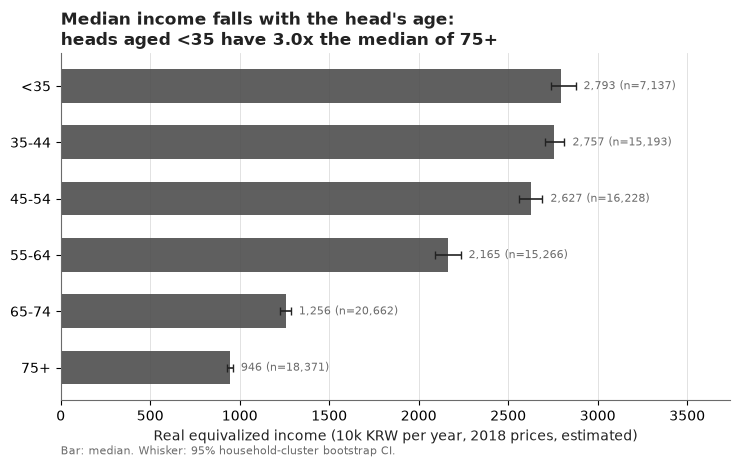

In [21]:
age = ci_chart(df, "age_group",
               "Median income falls with the head's age:\nheads aged {hi} have {ratio:.1f}x the median of {lo}",
               "context_age")

**Non-working heads: raw reason codes, used label-free.** The labels that came with the Kaggle description (and the original course notebook) do not match the data's profile, so the models use the raw code (`Not employed: code k`) and this section shows a profile per code instead of a chart by reason label. The documented label is listed for reference only.

In [22]:
from kwincome.codes import REASON

nonwork = df[df["occupation_code"].isna()].assign(
    reason_code=pd.to_numeric(df["reason_none_worker"], errors="coerce"))
prof = nonwork.groupby("reason_code").agg(
    n=("id", "size"), female_head_share=("female_head", "mean"), median_head_age=("age", "median"),
    widowed_share=("marriage_label", lambda s: s.eq("Widowed").mean()),
    median_eq_income=("eq_income", "median"))
prof.index = prof.index.astype(int)
prof.insert(0, "documented label (not trusted)", prof.index.map(lambda c: REASON.get(c, "nonresponse")))
display(prof.style.format({"n": "{:,}", "female_head_share": "{:.0%}", "median_head_age": "{:.1f}",
                          "widowed_share": "{:.0%}", "median_eq_income": "{:,.0f}"}))
c4, c3 = prof.loc[4], prof.loc[3]
print(f"non-working heads: {len(nonwork):,} rows; no reason code recorded: "
      f"{int(nonwork['reason_code'].isna().sum()):,}")
display(Markdown(
    f"**Data-quality finding.** Code 4 is documented as '{c4.iloc[0]}', yet its {c4['n']:,.0f} rows are "
    f"{c4['female_head_share']:.0%} female-headed with a median head age of {c4['median_head_age']:.0f} and "
    f"{c4['widowed_share']:.0%} widowed; only code 3 ('{c3.iloc[0]}', n = {c3['n']:,.0f}, median age "
    f"{c3['median_head_age']:.1f}) looks like students. The documented labels conflict with the data, so "
    f"reason codes are used without labels in every model, and no chart groups heads by reason label."))

,documented label (not trusted),n,female_head_share,median_head_age,widowed_share,median_eq_income
reason_code,,,,,,
0,nonresponse,1,0%,34.0,0%,"2,574"
1,no capable,"2,499",36%,73.0,35%,850
2,in military service,7,14%,27.0,14%,720
3,studying in school,52,44%,27.5,2%,"1,447"
4,prepare for school,704,95%,68.0,78%,814
5,prepare to apply job,326,34%,45.0,9%,"1,764"
6,house worker,"1,074",91%,68.0,58%,"1,186"
7,caring kids at home,"1,119",35%,65.0,28%,948
8,nursing,"4,275",47%,71.0,42%,920


non-working heads: 33,643 rows; no reason code recorded: 1,496


**Data-quality finding.** Code 4 is documented as 'prepare for school', yet its 704 rows are 95% female-headed with a median head age of 68 and 78% widowed; only code 3 ('studying in school', n = 52, median age 27.5) looks like students. The documented labels conflict with the data, so reason codes are used without labels in every model, and no chart groups heads by reason label.

Check passed: every head with an occupation code is an employed head (0 rows with a code but not employed; 0 with both a code and a non-work reason).


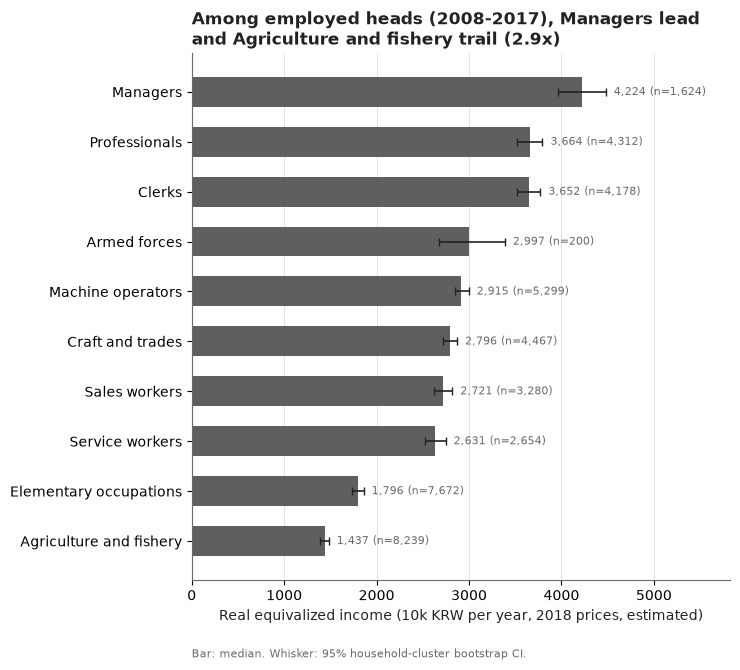

In [23]:
overlap = int((df["occupation_code"].notna() & (df["work_status"] != "Employed")).sum())
both = int((df["occupation_code"].notna() & pd.to_numeric(df["reason_none_worker"], errors="coerce").notna()).sum())
assert overlap == 0 and both == 0, (overlap, both)
print("Check passed: every head with an occupation code is an employed head "
      "(0 rows with a code but not employed; 0 with both a code and a non-work reason).")
occ_df = df[df["occ_consistent"] & df["occupation_major"].notna()].assign(
    occupation_group=lambda d: d["occupation_major"].map(OCC_MAJOR))
occ = ci_chart(occ_df, "occupation_group",
               "Among employed heads (2008-2017), {hi} lead\nand {lo} trail ({ratio:.1f}x)",
               "context_occupation", sort=True)

In [24]:
detail = occ_df[occ_df["occupation_label"] != "Unmapped"]
det = stats.median_ci_by_group(detail, "occupation_label", "eq_income", n_boot=N_BOOT)
det = det.merge(detail.groupby("occupation_label")["female_head"].mean().rename("female_head_share"),
                on="occupation_label").sort_values("median", ascending=False)
print(f"{len(det)} detailed occupations with n >= 100 (2008-2017, mapped codes)")
fmt = {"median": "{:,.0f}", "ci_low": "{:,.0f}", "ci_high": "{:,.0f}", "n": "{:,}",
       "female_head_share": "{:.0%}"}
cols = ["occupation_label", "n", "median", "ci_low", "ci_high", "female_head_share"]
display(Markdown("**Top 10**"), det[cols].head(10).style.format(fmt).hide(axis="index"))
display(Markdown("**Bottom 10**"), det[cols].tail(10).style.format(fmt).hide(axis="index"))
top_f, bot_f = det.head(10)["female_head_share"].mean(), det.tail(10)["female_head_share"].mean()
print(f"average female-head share: top 10 {top_f:.0%}, bottom 10 {bot_f:.0%}")

73 detailed occupations with n >= 100 (2008-2017, mapped codes)


**Top 10**

occupation_label,n,median,ci_low,ci_high,female_head_share
Administrative and management support manager,161,"4,848","3,918","5,932",0%
"Other construction, electricity and production managers",191,"4,711","3,483","5,555",1%
"Electrical, electronic and mechanical engineering technicians and testers",330,"4,680","4,416","5,092",1%
Finance and insurance related office workers,303,"4,539","3,841","5,139",13%
School teacher,416,"4,536","4,242","4,994",15%
Information system development expert,234,"4,165","3,526","5,370",8%
"Construction, electricity and production managers",309,"4,124","3,594","4,553",0%
Other sales and customer service managers,145,"4,080","3,174","4,480",11%
Administrative clerk,891,"3,961","3,701","4,233",6%
"Police, fire and prison related workers",357,"3,870","3,613","4,230",0%


**Bottom 10**

occupation_label,n,median,ci_low,ci_high,female_head_share
"Personnel related to visiting, stalls and mail-order sales",481,"1,995","1,763","2,263",38%
Simple workers in construction and mining,"1,000","1,939","1,868","2,067",4%
Medical and welfare related service workers,292,"1,807","1,519","2,040",93%
Sales-related simple employee,176,"1,724","1,477","2,056",43%
Housework and parenting helper,362,"1,644","1,390","1,813",96%
Simple food workers,502,"1,599","1,454","1,769",87%
Other service related simple employees,640,"1,541","1,397","1,655",34%
Crop cultivation worker,"7,768","1,411","1,362","1,457",23%
Cleaners and environmental cleaners,"1,898","1,349","1,270","1,429",52%
"Simple workers related to agriculture, forestry and fishing",322,"1,204","1,127","1,329",59%


average female-head share: top 10 6%, bottom 10 53%


## 10. Regions

*Takeaway: Seoul (2,288) and Gyeonggi (2,133) have the highest medians and Gyeongbuk (1,440) and Jeolla & Jeju (1,442) the lowest; these two regions also have the highest female-head shares (34% and 35%), so regional gaps likely mix place and household composition.*

The survey codes seven regions. Which provinces and metropolitan cities each code contains is an assumption (for example Busan and Ulsan with Gyeongnam, Incheon with Gyeonggi); see `kwincome.geo`. All data years pooled.

region_label,n,median,ci_low,ci_high,female_head_share
Seoul,"14,437","2,288","2,201","2,369",29%
Gyeonggi,"19,353","2,133","2,066","2,200",24%
Chungnam,"7,843","1,922","1,808","2,060",26%
Gyeongnam,"16,154","1,774","1,673","1,879",31%
Gangwon & Chungbuk,"6,927","1,692","1,584","1,785",26%
Jeolla & Jeju,"15,938","1,442","1,377","1,517",35%
Gyeongbuk,"12,205","1,440","1,374","1,505",34%


highest: Seoul 2,287.6; lowest: Gyeongbuk 1,440.2


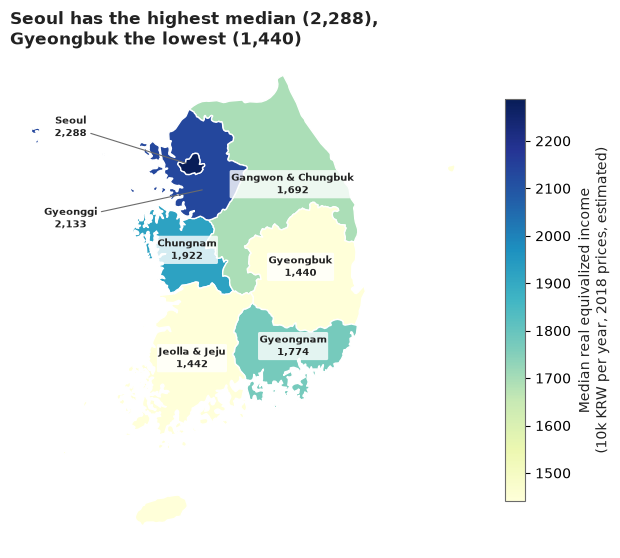

In [25]:
reg = stats.median_ci_by_group(df, "region_label", "eq_income", n_boot=N_BOOT)
reg = reg.merge(df.groupby("region_label")["female_head"].mean().rename("female_head_share"),
                on="region_label").sort_values("median", ascending=False)
display(reg.style.format({"median": "{:,.0f}", "ci_low": "{:,.0f}", "ci_high": "{:,.0f}",
                          "n": "{:,}", "female_head_share": "{:.0%}"}).hide(axis="index"))
gdf = geo.region_geodata(reg, "median")
r_hi = reg.iloc[0]
lowest = reg[reg["median"].round() == reg["median"].min().round()]
low_names = " and ".join(lowest["region_label"])
low_txt = f"{low_names} the lowest ({lowest['median'].min():,.0f})"
if len(lowest) > 1:
    low_txt = f"{low_names} tie for the lowest ({lowest['median'].min():,.0f})"
print(f"highest: {r_hi['region_label']} {r_hi['median']:,.1f}; lowest: "
      + ", ".join(f"{r} {m:,.1f}" for r, m in zip(lowest["region_label"], lowest["median"])))
fig = plots.plot_choropleth_static(
    gdf, "median", title=(f"{r_hi['region_label']} has the highest median ({r_hi['median']:,.0f}),\n"
                          f"{low_txt}"),
    label=f"Median real equivalized income\n({plots.INCOME_LABEL})")
plots.save(fig, "region_map");

Interactive version (renders only in a live Jupyter session or a trusted notebook; the static map above is the same data):

In [26]:
plots.choropleth_folium(gdf, "median", label=f"Median real equivalized income ({plots.INCOME_LABEL})")

## 11. Robustness

*Takeaway: the controlled gap stays between -7.2% and -8.2% across the four specifications; the explained share stays between 88% and 91% across the three specifications with a decomposition, and between 85% and 91% across pooled, male and female reference coefficients.*

Four specifications, each with the raw and fully controlled female-head coefficient and the pooled Oaxaca explained share (point estimates; the decomposition here uses 100 bootstrap draws only because its CIs are not reported). The winsorized row has no decomposition, because the decomposition function works on the unclipped outcome. The last row uses **all data years without occupation controls** (work status only), so both its sample and its controls differ from the main specification.

In [27]:
df["log_real_income"] = np.log(df["real_income"].where(df["real_income"] > 0))
specs = {
    "Main: log equivalized, 2008-2017, with occupation": dict(y="log_eq_income"),
    "Winsorized outcome (1st/99th pct)": dict(y="log_eq_income", winsor=True),
    "Not equivalized: log household income": dict(y="log_real_income"),
    "All data years 2005-2018, no occupation terms": dict(y="log_eq_income", include_occupation=False),
}
t0 = time.time()
rob = []
for name, kw in specs.items():
    sg = models.staged_gap(df, **kw)
    row = {"specification": name, "n": int(sg["n"].iloc[0]),
           "raw coef": sg["coef"].iloc[0], "final coef": sg["coef"].iloc[-1],
           "final gap %": sg["pct_gap"].iloc[-1],
           "final 95% CI %": f"[{sg['ci_low_pct'].iloc[-1]:.1f}, {sg['ci_high_pct'].iloc[-1]:.1f}]"}
    if not kw.get("winsor"):
        o = models.oaxaca(df, y=kw["y"], n_boot=100, include_occupation=kw.get("include_occupation", True))
        row["explained share of log gap"] = o["explained"] / o["total"]
    rob.append(row)
rob = pd.DataFrame(rob).set_index("specification")
print(f"time: {time.time() - t0:.0f}s")
r_small, r_big = rob["final gap %"].max(), rob["final gap %"].min()
x_lo, x_hi = rob["explained share of log gap"].min(), rob["explained share of log gap"].max()
print(f"final gap across the four specifications: {r_small:.1f}% to {r_big:.1f}%; explained share "
      f"{x_lo:.0%} to {x_hi:.0%} across the three specifications with a decomposition")
rob.style.format({"n": "{:,}", "raw coef": "{:.3f}", "final coef": "{:.3f}", "final gap %": "{:.1f}%",
                  "explained share of log gap": "{:.0%}"}, na_rep="n/a")

time: 60s
final gap across the four specifications: -7.2% to -8.2%; explained share 88% to 91% across the three specifications with a decomposition


,n,raw coef,final coef,final gap %,final 95% CI %,explained share of log gap
specification,,,,,,
"Main: log equivalized, 2008-2017, with occupation","66,449",-0.621,-0.076,-7.3%,"[-10.1, -4.5]",88%
Winsorized outcome (1st/99th pct),"66,449",-0.614,-0.078,-7.5%,"[-10.2, -4.8]",n/a
Not equivalized: log household income,"66,449",-0.962,-0.086,-8.2%,"[-11.0, -5.4]",91%
"All data years 2005-2018, no occupation terms","92,625",-0.605,-0.074,-7.2%,"[-9.8, -4.4]",88%


**Reference coefficients.** The headline decomposition uses pooled coefficients. Using the male-headed or female-headed households' own coefficients instead (classic two-fold; unexplained = total - explained) shows how much the split depends on that choice. CIs are shown for the pooled reference only; the other two are point estimates (`n_boot=0`).

In [28]:
refs = {"pooled": oax}
refs.update({r: models.oaxaca(df, n_boot=0, reference=r) for r in ("male", "female")})
ref_table = pd.DataFrame({
    r: {"explained": o["explained"], "unexplained": o["unexplained"],
        "explained share of the log gap": o["explained"] / o["total"],
        "explained 95% CI": (f"[{o['ci']['explained'][0]:.3f}, {o['ci']['explained'][1]:.3f}]"
                             if r == "pooled" else "not computed")}
    for r, o in refs.items()}).T
ref_table.index.name = "reference coefficients"
ref_lo = min(o["explained"] / o["total"] for o in refs.values())
ref_hi = max(o["explained"] / o["total"] for o in refs.values())
print(f"explained share of the log gap across references: {ref_lo:.0%} to {ref_hi:.0%}")
ref_table.style.format({"explained": "{:.3f}", "unexplained": "{:.3f}",
                        "explained share of the log gap": "{:.1%}"})

explained share of the log gap across references: 85% to 91%


,explained,unexplained,explained share of the log gap,explained 95% CI
reference coefficients,,,,
pooled,0.545,0.076,87.7%,"[0.515, 0.575]"
male,0.563,0.058,90.7%,not computed
female,0.527,0.094,84.8%,not computed


## 12. Limitations

- **Estimated unit, inferred income year.** Income is read as 10k KRW per year (estimated), and Kaggle `year` as the income reference year (inferred from the sample design: fielded the following year); neither is confirmed by a codebook.
- **No survey weights.** The source survey is reported to oversample low-income households; without weights, results describe this sample, not Korea.
- **Household heads, not individuals.** The comparison is female- vs male-headed households. Who becomes a head (widowhood, divorce, living alone in old age) is itself selected, so the gap mixes many situations.
- **Heads change within a household.** The same id can be male-headed one year and female-headed later (for example after widowhood), so a household can sit on both sides of the comparison over time.
- **Panel composition.** Most households enter in 2005 and a large group joins in 2011 (appears consistent with a reported new sample); the panel ages and loses households in between. The trend is not a national trend.
- **Head-only covariates, household income.** Education, work and occupation describe the head only, while income includes every member's earnings and transfers.
- **"Explained" means composition.** Marital status and household size largely restate what female headship means (no spouse, often living alone, fewer earners), so the explained share should not be read as a set of independent causes.
- **Association, not causation.** The unexplained part is a residual after observed controls, not a measure of discrimination; unobserved factors (hours, wealth, transfers, health) sit inside it.
- **Occupation coding.** Occupation codes are only comparable in data years 2008-2017, so models with occupation use those years.
- **Non-work reason labels are not trusted.** The documented labels conflict with the data (Section 9), so non-working heads enter the models by raw reason code, without labels, and no result is interpreted by reason.
- **Marital status labels are inferred.** Codes 1-6 are labelled from the source survey's usual convention and the profile in Section 2, not from a codebook.
- **Region grouping is assumed.** The mapping from provinces to the seven survey regions is an inference.
- **Quantile CIs are not clustered by household** and are likely too narrow. Staged OLS and Oaxaca CIs are household-clustered.
- **Decomposition choices.** The pooled reference coefficients are one standard choice; male or female reference coefficients move the explained share within the range shown in Section 11.
- **Log models exclude income <= 0** (counts printed in Sections 3 and 6).

In [29]:
# Consistency check: the numbers quoted in Section 1 are recomputed here and must match.
quoted = {
    "female-head share": (f"{share['female']:.0%}", "30%"),
    "raw median gap": (f"{eq_gap:.0%}", "-52%"),
    "log gap": (f"{T:.3f}", "0.621"),
    "raw staged %": (f"{s_raw['pct_gap']:.0f}%", "-46%"),
    "final gap": (f"{s_fin['pct_gap']:.1f}%", "-7.3%"),
    "final CI": (f"{s_fin['ci_low_pct']:.1f}% to {s_fin['ci_high_pct']:.1f}%", "-10.1% to -4.5%"),
    "explained share": (f"{E / T:.0%}", "88%"),
    "work/occupation share": (f"{contrib.loc['Work / occupation', 'share_of_log_gap']:.0%}", "29%"),
    "education share": (f"{contrib.loc['Education', 'share_of_log_gap']:.0%}", "28%"),
    "unexplained": (f"{U:.3f}", "0.076"),
    "unexplained share": (f"{U / T:.0%}", "12%"),
    "unexplained CI": (f"{ci['unexplained'][0]:.3f} to {ci['unexplained'][1]:.3f}", "0.045 to 0.107"),
    "quantile range": (f"{q_small:.0f}% to {q_big:.0f}%", "6% to 11%"),
    "quantile widest": (f"{q_widest:.0%}", "90%"),
    "robustness range": (f"{r_big:.1f}% and {r_small:.1f}%", "-8.2% and -7.2%"),
    "household size": (f"{size.loc['Female', 'mean household size']:.2f} vs "
                       f"{size.loc['Male', 'mean household size']:.2f}", "1.50 vs 2.90"),
    "single-person share": (f"{size.loc['Female', 'share single-person']:.0%}", "68%"),
    "per-person gap": (f"{pp_gap:.0%}", "-29%"),
    "work/occ, education log points": (f"{contrib.loc['Work / occupation', 'explained']:.3f}, "
                                       f"{contrib.loc['Education', 'explained']:.3f}", "0.181, 0.171"),
    "trend growth": (f"{growth:.0%}", "58%"),
    "trend ratio range": (f"{ratio_lo:.0%} to {ratio_hi:.0%}", "45% to 51%"),
    "mapping rate": (f"{report['occupation_mapping_rate']:.1%}", "89.8%"),
    "top regions": (f"{reg.iloc[0]['median']:,.0f}, {reg.iloc[1]['median']:,.0f}", "2,288, 2,133"),
    "lowest regions": (", ".join(f"{r.region_label} {r.median:,.0f} ({r.female_head_share:.0%} female-headed)"
                                 for r in reg.iloc[::-1].head(2).itertuples()),
                       "Gyeongbuk 1,440 (34% female-headed), Jeolla & Jeju 1,442 (35% female-headed)"),
    "occupation female shares": (f"{bot_f:.0%} vs {top_f:.0%}", "53% vs 6%"),
    "explained share range": (f"{x_lo:.0%} and {x_hi:.0%}", "88% and 91%"),
    "head change ids": (f"{n_change:,} ({n_gender_change:,} gender)", "1,428 (1,284 gender)"),
    "widowed profile": (f"{wid['female_head_share']:.0%}, age {wid['median_head_age']:.0f}, size "
                        f"{wid['median_household_size']:.0f}", "89%, age 74, size 1"),
    "married profile": (f"{mar.loc[1, 'female_head_share']:.0%}, size {mar.loc[1, 'median_household_size']:.0f}",
                        "3%, size 3"),
    "never married age": (f"{mar.loc[5, 'median_head_age']:.0f}", "36"),
    "female heads widowed": (f"{fem_widowed:.0%}", "68%"),
    "marital + size share": (f"{comp / T:.0%}", "19%"),
    "reference range": (f"{ref_lo:.0%} to {ref_hi:.0%}", "85% to 91%"),
    "new ids 2011": (f"{new_2011:,}", "1,878"),
    "head age drift": (f"{age_first} to {age_last}", "53 to 64"),
    "age + education + work share": (f"{head_chars / T:.0%}", "69%"),
    "unexplained as % income": (f"{np.expm1(U):.1%} higher, {-np.expm1(-U):.1%} lower",
                                "7.9% higher, 7.3% lower"),
    "wave 1 households": (f"{raw.loc[raw['year'].eq(2005), 'id'].nunique():,}", "7,072"),
    "trend income years": (f"{first} and {last}", "2005 and 2018"),
    "staged before region & year": (f"{staged.iloc[-2]['pct_gap']:.1f}%", "-6.0%"),
    "explained log points and CI": (f"{E:.3f} ({ci['explained'][0]:.3f} to {ci['explained'][1]:.3f})",
                                    "0.545 (0.515 to 0.575)"),
    "quantile range (1 decimal)": (f"{q_small:.1f}% to {q_big:.1f}%", "6.3% to 11.2%"),
    "quantile range 10th-75th": (f"{-qgap.loc[qgap['q'] <= 0.75, 'pct_gap'].max():.0f}% to "
                                 f"{-qgap.loc[qgap['q'] <= 0.75, 'pct_gap'].min():.0f}%", "6% to 9%"),
    "reference shares": (f"{refs['male']['explained'] / refs['male']['total']:.1%}, "
                         f"{refs['female']['explained'] / refs['female']['total']:.1%}", "90.7%, 84.8%"),
    "reason code 4": (f"{c4['n']:,.0f}, {c4['female_head_share']:.0%}, age {c4['median_head_age']:.0f}, "
                      f"{c4['widowed_share']:.0%} widowed", "704, 95%, age 68, 78% widowed"),
}
bad = {label: (value, text) for label, (value, text) in quoted.items() if text != value}
assert not bad, bad
print("All numbers quoted in the summary match the computed results.")

All numbers quoted in the summary match the computed results.


## 13. Explore it yourself

This section needs a running kernel (the widget does not render on GitHub). Pick a measure and a grouping to redraw the median chart with 95% household-cluster bootstrap CIs (200 draws for speed).

interactive(children=(Dropdown(description='metric', options=('Real equivalized income', 'Real household incom…

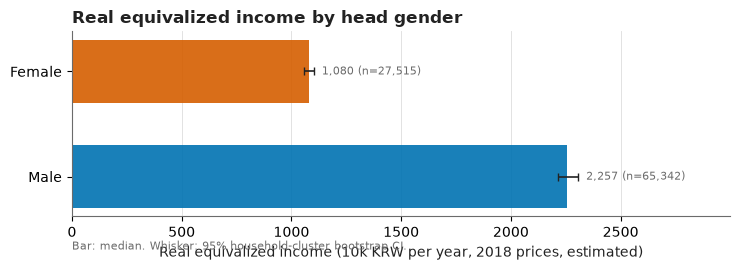

In [30]:
import ipywidgets as widgets

METRICS = {"Real equivalized income": "eq_income", "Real household income": "real_income",
           "Real income per person": "income_pp"}
GROUPS = {"Head gender": "gender_label", "Education": "education_label", "Age group": "age_group",
          "Work status": "work_status", "Region": "region_label"}


def explore(metric, grouping):
    s = stats.median_ci_by_group(df, GROUPS[grouping], METRICS[metric], n_boot=200)
    plots.plot_ci_bars(s, x=GROUPS[grouping], title=f"{metric} by {grouping.lower()}",
                       xlabel=f"{metric} ({plots.INCOME_LABEL})")


widgets.interact(explore, metric=list(METRICS), grouping=list(GROUPS));